In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import  sys

In [7]:
from pathlib import Path

for path in Path("/workspace").rglob("cortexhr_helpers.py"):
    if ".Trash-0" not in path.parts:
        print(path)

In [31]:

root = Path("/workspace")
print("=== Python files ===")
for path in sorted(root.rglob("*.py")):
    if ".Trash-0" not in path.parts and "__pycache__" not in path.parts:
        print(path)
print("\n=== Searching for required functions ===")
for path in root.rglob("*.py"):
    if ".Trash-0" in path.parts or "__pycache__" in path.parts:
        continue
    try:
        code = path.read_text(encoding="utf-8")
        if "binary_report" in code or "risk_bands" in code:
            print("Found in:", path)
    except (OSError, UnicodeDecodeError):
        pass

=== Python files ===
/workspace/data/raw/feature.py
/workspace/src/.ipynb_checkpoints/feature-checkpoint.py
/workspace/src/.ipynb_checkpoints/features-checkpoint.py
/workspace/src/feature.py
/workspace/src/features.py

=== Searching for required functions ===


In [32]:
"""
Calculate the metrics using binary_report().
Draw and interpret the calibration curve.
Create High, Medium and Low risk bands.
Measure how many actual leavers fall in the High-risk band.
Write the one-page manager note and save the chart.     in total 5 step we will compelete this
"""

'\nCalculate the metrics using binary_report().\nDraw and interpret the calibration curve.\nCreate High, Medium and Low risk bands.\nMeasure how many actual leavers fall in the High-risk band.\nWrite the one-page manager note and save the chart.     in total 5 step we will compelete this\n'

In [13]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score,
    accuracy_score
)
sys.path.insert(0, "/workspace/src")
from features import build_pipeline
# Load Task 2 output
df_model = pd.read_csv("/workspace/data/processed/attrition_features.csv")
target = "left_within_12m"
excluded_columns = [
    "row_id", "employee_id", "observation_date", "source",
    "voluntary_left_within_12m", "exit_date", "resignation_date",
    "exit_reason", "exit_interview_done", "fnf_settlement_amount"
]
X = df_model.drop(columns=excluded_columns + [target], errors="ignore")
y = df_model[target]
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(
    include=["object", "category", "string", "bool", "boolean"]
).columns.tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X, y))
model = Pipeline([
    ("preprocessing", build_pipeline(numeric_columns, categorical_columns)),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])
probabilities = cross_val_predict(
    model, X, y, cv=folds, method="predict_proba"
)
oof_scores = probabilities[:, 1]

In [22]:
from sklearn.calibration import calibration_curve,CalibratedClassifierCV

,Score
ROC-AUC,0.701
PR-AUC,0.296
Precision,0.000
Recall,0.000
F1-score,0.000
Accuracy,0.853


Brier score: 0.117
Log loss: 0.386


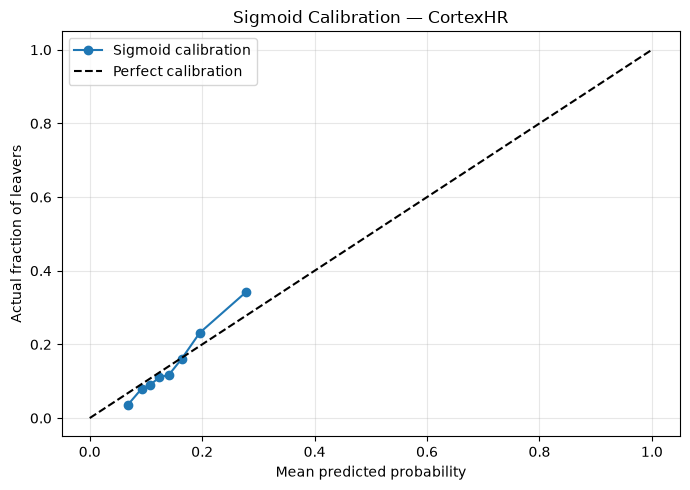

Chart saved.


In [34]:
sigmoid_model = CalibratedClassifierCV(
    model,
    method="sigmoid",
    cv=3
)
probabilities = cross_val_predict(
    sigmoid_model, X, y, cv=folds, method="predict_proba"
)

sigmoid_oof_scores = probabilities[:, 1]

display(binary_report(y, sigmoid_oof_scores).to_frame("Score").round(3))

print("Brier score:", round(brier_score_loss(y, sigmoid_oof_scores), 3))
print("Log loss:", round(log_loss(y, sigmoid_oof_scores), 3))

actual_rate, predicted_rate = calibration_curve(
    y, sigmoid_oof_scores, n_bins=8, strategy="quantile"
)
plt.figure(figsize=(7, 5))
plt.plot(predicted_rate, actual_rate, marker="o", label="Sigmoid calibration")
plt.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Actual fraction of leavers")
plt.title("Sigmoid Calibration — CortexHR")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
report_dir = Path("/workspace/reports")
report_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(report_dir / "sigmoid_calibration_curve.png", dpi=150)
plt.show()

print("Chart saved.")

In [20]:
def risk_bands(scores):
    scores = pd.Series(np.asarray(scores))
    ranking = scores.rank(method="first", ascending=False)

    high_limit = int(np.ceil(len(scores) * 0.10))
    medium_limit = int(np.ceil(len(scores) * 0.30))

    bands = np.where(
        ranking <= high_limit, "High",
        np.where(ranking <= medium_limit, "Medium", "Low")
    )

    return pd.Series(bands, name="risk_band")

In [21]:
risk_df = pd.DataFrame({
    "actual_left": y.reset_index(drop=True),
    "predicted_risk": np.asarray(oof_scores)
})

risk_df["risk_band"] = risk_bands(risk_df["predicted_risk"])

band_order = ["High", "Medium", "Low"]

band_counts = (
    risk_df["risk_band"]
    .value_counts()
    .reindex(band_order, fill_value=0)
)

band_summary = pd.DataFrame({
    "record_count": band_counts,
    "percentage": (band_counts / len(risk_df) * 100).round(1)
})
band_summary

,record_count,percentage
risk_band,,
High,239,10.0
Medium,478,20.0
Low,1672,70.0


In [35]:
band_summary = risk_df.groupby("risk_band").agg(
    record_count=("actual_left", "size"),
    actual_leavers=("actual_left", "sum")
).reindex(["High", "Medium", "Low"])

band_summary["leaver_rate_pct"] = (
    band_summary["actual_leavers"] /
    band_summary["record_count"] * 100
).round(1)

band_summary["share_of_all_leavers_pct"] = (
    band_summary["actual_leavers"] /
    risk_df["actual_left"].sum() * 100
).round(1)
band_summary

,record_count,actual_leavers,leaver_rate_pct,share_of_all_leavers_pct
risk_band,,,,
High,239,85,35.6,24.4
Medium,478,112,23.4,32.1
Low,1672,152,9.1,43.6


In [ ]:
#Manager Notes

In [36]:
report_dir = Path("/workspace/reports")
report_dir.mkdir(parents=True, exist_ok=True)

manager_note = """# CortexHR Attrition Model — Evaluation Note

## Purpose
The CortexHR model estimates employee attrition risk using available employee features. It helps HR prioritize follow-up and support, not make automatic employment decisions.

## Model performance
Logistic Regression achieved a ROC-AUC of 0.702, PR-AUC of 0.293, and accuracy of 0.691. ROC-AUC measures ranking ability, while PR-AUC summarizes precision and recall for the leaver class. Accuracy alone does not show how effectively the model identifies employees who leave.

## Risk-band findings
The High band contains 239 records, including 85 actual leavers. Its leaver rate is 35.6%, and it captures 24.4% of all actual leavers. The Medium band contains 478 records and 112 actual leavers. The Low band contains 1,672 records and 152 actual leavers. The top 10% captures approximately 2.44 times the share of leavers expected from random selection of 10% of records.

## Understanding the scores
The original calibration curve indicates that the model tends to assign higher risks than observed departure rates justify. Its scores should not be treated as reliable individual probabilities. Sigmoid calibration improved the Brier score in our experiment, but requires further validation.

## Recommended use and limitations
HR can use the ranked list to prioritize confidential, supportive check-ins and investigate workplace issues. A high score does not guarantee departure, and a low score does not guarantee retention. HR must review each case in context, protect privacy, assess fairness, and never rely on a score alone for employment decisions. Risk-band counts must be reconciled to unique employees before producing an employee-level action list.

## Conclusion
The baseline is a starting point for prioritizing reviews, not a decision-making system ready for operational use. Calibration and generalization require further validation.
"""

note_path = report_dir / "manager_evaluation_note.md"
note_path.write_text(manager_note, encoding="utf-8")
print("Manager note saved:", note_path)
print(
    "Calibration chart exists:",
    (report_dir / "calibration_curve.png").exists()
)

Manager note saved: /workspace/reports/manager_evaluation_note.md
Calibration chart exists: True
